<a href="https://colab.research.google.com/github/Dineshkumar-DK19/GCEE-HCL/blob/main/Phase%202%20-%20ML/UNIT%201%20-%20Machine%20Learning/Learning%20Tasks/Supervised%20/Logistic_Regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

**Student Pass/Fail Prediction**


The goal of this project is to predict whether a student will pass or fail based on their attendance percentage, homework completion percentage, midterm score, and weekly study hours

In [15]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

In [4]:
df = pd.read_csv("student_data.csv")
df.head()

,student_id,attendance_pct,homework_pct,midterm_score,study_hours_per_week,pass
0,1,95,92,88,12,1
1,2,88,85,79,10,1
2,3,60,55,58,4,0
3,4,72,70,65,6,1
4,5,40,45,50,3,0


In [8]:
#input
X = df[
    [
        "attendance_pct",
        "homework_pct",
        "midterm_score",
        "study_hours_per_week"
    ]
]

#target
y = df["pass"]  # 1 = Pass, 0 = Fail

In [9]:
#splitting data for traning and testing
X_train, X_test, y_train, y_test = train_test_split(X,y,test_size=0.2,random_state=42,stratify=y)


In [11]:
#creating the model
model = LogisticRegression(max_iter=1000)
model.fit(X_train, y_train)

LogisticRegression(max_iter=1000)

In [13]:
# Predict pass/fail for the test data
y_pred = model.predict(X_test)

In [16]:
#evaluation
print("Accuracy:", accuracy_score(y_test, y_pred))
print("\nClassification Report:\n", classification_report(y_test, y_pred))
print("\nConfusion Matrix:\n", confusion_matrix(y_test, y_pred))

Accuracy: 1.0

Classification Report:
               precision    recall  f1-score   support

           0       1.00      1.00      1.00         8
           1       1.00      1.00      1.00        12

    accuracy                           1.00        20
   macro avg       1.00      1.00      1.00        20
weighted avg       1.00      1.00      1.00        20


Confusion Matrix:
 [[ 8  0]
 [ 0 12]]


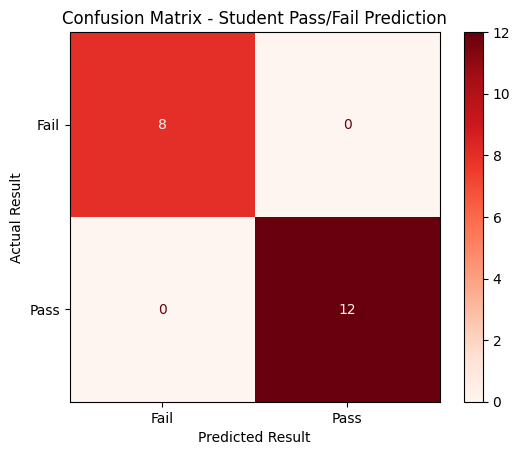

In [21]:
import matplotlib.pyplot as plt
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=[0, 1],
    display_labels=["Fail", "Pass"],
    cmap="Reds"
)

plt.title("Confusion Matrix - Student Pass/Fail Prediction")
plt.xlabel("Predicted Result")
plt.ylabel("Actual Result")
plt.show()